In [14]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()

X = digits.data / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

Y_train = np.eye(10)[y_train]
Y_test = np.eye(10)[y_test]

print("Training inputs:", X_train.shape)
print("Training labels:", Y_train.shape)
print("Test inputs:", X_test.shape)
print("Test labels:", Y_test.shape)

Training inputs: (1257, 64)
Training labels: (1257, 10)
Test inputs: (540, 64)
Test labels: (540, 10)


In [3]:
def initialize_parameters(width, seed=42):
    rng = np.random.default_rng(seed)

    return {
        "W1": rng.normal(0.0, 0.01, size=(64, width)),
        "b1": np.zeros((1, width)),
        "W2": rng.normal(0.0, 0.01, size=(width, width)),
        "b2": np.zeros((1, width)),
        "W3": rng.normal(0.0, 0.01, size=(width, 10)),
        "b3": np.zeros((1, 10))
    }


parameters = initialize_parameters(width=16)

for name, value in parameters.items():
    print(name, value.shape)

W1 (64, 16)
b1 (1, 16)
W2 (16, 16)
b2 (1, 16)
W3 (16, 10)
b3 (1, 10)


In [16]:
def relu(z):
    return np.maximum(0.0, z)


def softmax(z):
    shifted = z - np.max(z, axis=1, keepdims=True)
    exp_values = np.exp(shifted)

    return exp_values / np.sum(
        exp_values,
        axis=1,
        keepdims=True
    )


def forward(X, parameters):
    Z1 = X @ parameters["W1"] + parameters["b1"]
    A1 = relu(Z1)

    Z2 = A1 @ parameters["W2"] + parameters["b2"]
    A2 = relu(Z2)

    Z3 = A2 @ parameters["W3"] + parameters["b3"]
    probabilities = softmax(Z3)

    cache = {
        "X": X,
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2,
        "Z3": Z3,
        "probabilities": probabilities
    }

    return probabilities, cache


probabilities, cache = forward(X_train[:32], parameters)

assert probabilities.shape == (32, 10)
assert np.allclose(
    probabilities.sum(axis=1),
    1.0,
    atol=1e-6,
    rtol=0.0
)

print("Output shape:", probabilities.shape)
print("First prediction:", probabilities[0])
print("Probability sum:", probabilities[0].sum())

Output shape: (32, 10)
First prediction: [0.10000007 0.09999837 0.0999954  0.1000008  0.09999682 0.10000109
 0.10000277 0.10000046 0.10000342 0.10000081]
Probability sum: 1.0000000000000002


In [17]:
def cross_entropy(logits, Y):
    shifted = logits - np.max(
        logits,
        axis=1,
        keepdims=True
    )

    log_probabilities = shifted - np.log(
        np.sum(np.exp(shifted), axis=1, keepdims=True)
    )

    return -np.mean(
        np.sum(Y * log_probabilities, axis=1)
    )


probabilities, cache = forward(X_train, parameters)
initial_loss = cross_entropy(cache["Z3"], Y_train)

print(f"Initial loss: {initial_loss:.6f}")
print(f"Expected approximately: {np.log(10):.6f}")

Initial loss: 2.302586
Expected approximately: 2.302585


In [24]:
def backward(parameters, cache, Y):
    batch_size = Y.shape[0]

    dZ3 = (cache["probabilities"] - Y) / batch_size

    dW3 = cache["A2"].T @ dZ3
    db3 = np.sum(dZ3, axis=0, keepdims=True)

    dA2 = dZ3 @ parameters["W3"].T
    dZ2 = dA2 * (cache["Z2"] > 0)

    dW2 = cache["A1"].T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ parameters["W2"].T
    dZ1 = dA1 * (cache["Z1"] > 0)

    dW1 = cache["X"].T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2,
        "W3": dW3,
        "b3": db3
    }

In [25]:
def gradient_check(parameters, X, Y, checks=10, epsilon=1e-5):
    rng = np.random.default_rng(123)

    _, cache = forward(X, parameters)
    analytical_gradients = backward(parameters, cache, Y)

    weight_names = ["W1", "W2", "W3"]
    sizes = [parameters[name].size for name in weight_names]
    boundaries = np.cumsum(sizes)

    selected = rng.choice(
        sum(sizes),
        size=checks,
        replace=False
    )

    passed = 0

    for flat_index in selected:
        layer = int(
            np.searchsorted(boundaries, flat_index, side="right")
        )
        name = weight_names[layer]

        offset = 0 if layer == 0 else boundaries[layer - 1]
        local_index = int(flat_index - offset)

        index = np.unravel_index(
            local_index,
            parameters[name].shape
        )

        original = parameters[name][index]

        try:
            parameters[name][index] = original + epsilon
            _, plus_cache = forward(X, parameters)
            loss_plus = cross_entropy(plus_cache["Z3"], Y)

            parameters[name][index] = original - epsilon
            _, minus_cache = forward(X, parameters)
            loss_minus = cross_entropy(minus_cache["Z3"], Y)
        finally:
            parameters[name][index] = original

        numerical = (loss_plus - loss_minus) / (2 * epsilon)
        analytical = analytical_gradients[name][index]

        relative_error = abs(numerical - analytical) / max(
            1e-8,
            abs(numerical) + abs(analytical)
        )

        success = relative_error < 1e-6
        passed += int(success)

        print(
            f"{name}{index}: "
            f"analytical={analytical:.8e}, "
            f"numerical={numerical:.8e}, "
            f"relative error={relative_error:.3e}, "
            f"{'PASS' if success else 'FAIL'}"
        )

    print(f"\nPassed: {passed}/{checks}")

    assert passed >= 9, "Gradient check failed."


# Use a separate parameter set with larger weights to reduce
# cancellation errors when comparing very small gradients.
check_parameters = initialize_parameters(width=16, seed=7)

for name in ("W1", "W2", "W3"):
    check_parameters[name] *= 10.0

gradient_check(
    check_parameters,
    X_train[:8],
    Y_train[:8]
)

W1(np.int64(1), np.int64(6)): analytical=0.00000000e+00, numerical=0.00000000e+00, relative error=0.000e+00, PASS
W3(np.int64(2), np.int64(4)): analytical=3.42597440e-03, numerical=3.42597442e-03, relative error=2.727e-09, PASS
W1(np.int64(19), np.int64(12)): analytical=8.47784495e-04, numerical=8.47784509e-04, relative error=8.572e-09, PASS
W1(np.int64(30), np.int64(0)): analytical=-2.51586044e-03, numerical=-2.51586045e-03, relative error=2.069e-09, PASS
W1(np.int64(61), np.int64(1)): analytical=0.00000000e+00, numerical=0.00000000e+00, relative error=0.000e+00, PASS
W1(np.int64(53), np.int64(1)): analytical=0.00000000e+00, numerical=0.00000000e+00, relative error=0.000e+00, PASS
W1(np.int64(22), np.int64(14)): analytical=0.00000000e+00, numerical=0.00000000e+00, relative error=0.000e+00, PASS
W1(np.int64(15), np.int64(13)): analytical=0.00000000e+00, numerical=0.00000000e+00, relative error=0.000e+00, PASS
W1(np.int64(16), np.int64(9)): analytical=0.00000000e+00, numerical=0.0000000

In [20]:
def accuracy(probabilities, y):
    predictions = np.argmax(probabilities, axis=1)
    return np.mean(predictions == y)


def train(width, learning_rate, epochs=50, batch_size=32):
    parameters = initialize_parameters(width, seed=42)
    rng = np.random.default_rng(42)

    history = []

    for epoch in range(epochs):
        indices = rng.permutation(len(X_train))

        for start in range(0, len(X_train), batch_size):
            batch_indices = indices[start:start + batch_size]

            X_batch = X_train[batch_indices]
            Y_batch = Y_train[batch_indices]

            _, cache = forward(X_batch, parameters)
            gradients = backward(parameters, cache, Y_batch)

            for name in parameters:
                parameters[name] -= (
                    learning_rate * gradients[name]
                )

        train_probabilities, train_cache = forward(
            X_train,
            parameters
        )

        loss = cross_entropy(train_cache["Z3"], Y_train)
        train_accuracy = accuracy(train_probabilities, y_train)

        history.append(loss)

        print(
            f"Width={width:2d} | "
            f"LR={learning_rate:.3f} | "
            f"Epoch={epoch + 1:02d}/{epochs} | "
            f"Loss={loss:.4f} | "
            f"Train accuracy={train_accuracy:.2%}"
        )

    return parameters, history

In [21]:
results = []

for width in (16, 64):
    for learning_rate in (0.001, 0.01, 0.1):
        parameters, history = train(
            width=width,
            learning_rate=learning_rate
        )

        test_probabilities, _ = forward(X_test, parameters)
        test_accuracy = accuracy(test_probabilities, y_test)

        results.append({
            "width": width,
            "learning_rate": learning_rate,
            "parameters": parameters,
            "loss_history": history,
            "test_accuracy": test_accuracy
        })

print("\nFINAL RESULTS")
print(f"{'Width':>6} {'Learning rate':>15} {'Test accuracy':>15}")

for result in results:
    print(
        f"{result['width']:>6} "
        f"{result['learning_rate']:>15.3f} "
        f"{result['test_accuracy']:>14.2%}"
    )

Width=16 | LR=0.001 | Epoch=01/50 | Loss=2.3026 | Train accuracy=10.02%
Width=16 | LR=0.001 | Epoch=02/50 | Loss=2.3026 | Train accuracy=10.02%
Width=16 | LR=0.001 | Epoch=03/50 | Loss=2.3026 | Train accuracy=15.59%
Width=16 | LR=0.001 | Epoch=04/50 | Loss=2.3026 | Train accuracy=10.02%
Width=16 | LR=0.001 | Epoch=05/50 | Loss=2.3026 | Train accuracy=19.01%
Width=16 | LR=0.001 | Epoch=06/50 | Loss=2.3026 | Train accuracy=10.10%
Width=16 | LR=0.001 | Epoch=07/50 | Loss=2.3026 | Train accuracy=10.10%
Width=16 | LR=0.001 | Epoch=08/50 | Loss=2.3026 | Train accuracy=14.88%
Width=16 | LR=0.001 | Epoch=09/50 | Loss=2.3026 | Train accuracy=17.18%
Width=16 | LR=0.001 | Epoch=10/50 | Loss=2.3026 | Train accuracy=10.10%
Width=16 | LR=0.001 | Epoch=11/50 | Loss=2.3026 | Train accuracy=10.10%
Width=16 | LR=0.001 | Epoch=12/50 | Loss=2.3026 | Train accuracy=10.10%
Width=16 | LR=0.001 | Epoch=13/50 | Loss=2.3026 | Train accuracy=10.10%
Width=16 | LR=0.001 | Epoch=14/50 | Loss=2.3026 | Train accuracy

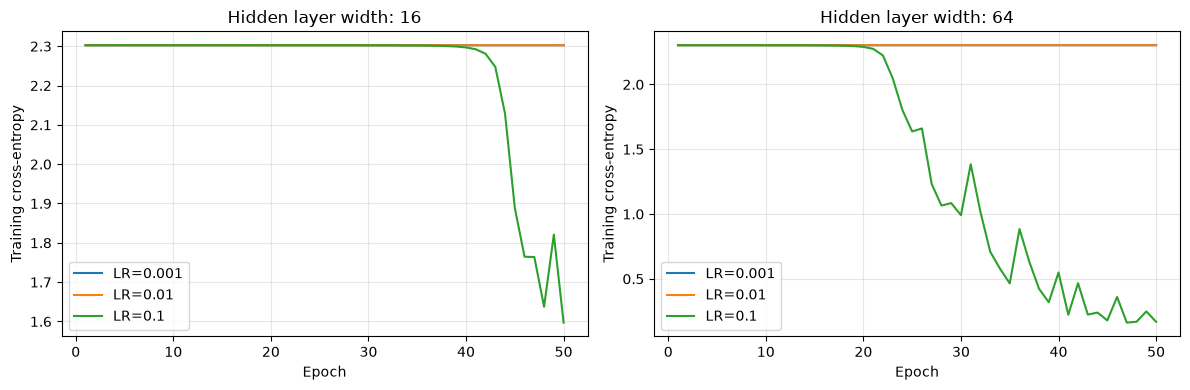

In [22]:
Path("results").mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, width in zip(axes, (16, 64)):
    for result in results:
        if result["width"] == width:
            ax.plot(
                range(1, len(result["loss_history"]) + 1),
                result["loss_history"],
                label=f"LR={result['learning_rate']}"
            )

    ax.set_title(f"Hidden layer width: {width}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training cross-entropy")
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("results/loss_curves.png", dpi=150)
plt.show()

In [23]:
def benchmark(parameters, X_batch, Y_batch, runs=100):
    # Warm up before collecting measurements.
    for _ in range(10):
        _, cache = forward(X_batch, parameters)
        backward(parameters, cache, Y_batch)

    forward_times = []

    for _ in range(runs):
        start = perf_counter()
        forward(X_batch, parameters)
        forward_times.append(perf_counter() - start)

    _, cache = forward(X_batch, parameters)
    backward_times = []

    for _ in range(runs):
        start = perf_counter()
        backward(parameters, cache, Y_batch)
        backward_times.append(perf_counter() - start)

    return (
        np.median(forward_times) * 1000,
        np.median(backward_times) * 1000
    )


print("\nTIMING: MEDIAN OF 100 RUNS")

for width in (16, 64):
    result = next(
        result
        for result in results
        if result["width"] == width
        and result["learning_rate"] == 0.1
    )

    forward_ms, backward_ms = benchmark(
        result["parameters"],
        X_train[:32],
        Y_train[:32]
    )

    print(
        f"Width={width}: "
        f"forward={forward_ms:.4f} ms, "
        f"backward={backward_ms:.4f} ms"
    )


TIMING: MEDIAN OF 100 RUNS
Width=16: forward=0.1368 ms, backward=0.1464 ms
Width=64: forward=0.1946 ms, backward=0.2683 ms
